# Forecast reliability features: 5-minute results

Eighteen features describing the recent accuracy of AEMO's own forecast were added to the baseline 5-minute
MLP. With them, the MLP's test error falls by 5–14% in every state, and all 15 seed runs improve.

**The features**

The model already uses AEMO's P5MIN forecast as an input, but that forecast's accuracy varies
considerably over time. The reliability features summarise AEMO's recent performance so the model can
learn when to rely on it. Each one compares a forecast issued 5 or 30 minutes earlier with the price that
was realised, so every value is known at forecast time.

| Feature | Measures | Windows |
|---|---|---|
| `reliability_rrp_errXX_mean_W` | mean error (bias) | 1 h, 6 h, 24 h |
| `reliability_rrp_errXX_abs_W` | mean absolute error | 1 h, 6 h, 24 h |
| `reliability_warningsXX_288` | number of $300+ forecasts | 24 h |
| `reliability_false_alarmsXX_288` | $300+ forecasts where the price stayed below | 24 h |
| `reliability_missedXX_288` | $300+ prices that were not forecast | 24 h |

Nine features are computed for each of AEMO's 5- and 30-minute forecasts, 18 in total, which takes the
model from 83 to 101 inputs. They are built by `reliability_features.py` and appended to the prepared
data, so the shared pipeline is unchanged.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from reliability_features import baseline_experiment, reliability_features

AEMO, OURS, INK, MUTED = "#2a78d6", "#1baf7a", "#0b0b0b", "#52514e"
pd.set_option("display.float_format", "{:.2f}".format)
warnings.filterwarnings("ignore", category=DeprecationWarning)  # noisy pandas/numpy timedelta notices

The features are built below for Victoria from the prepared 5-minute data

In [2]:
experiment = baseline_experiment("VIC1", horizon=5)
timeline = (pd.concat([experiment.prepared.train_timeline, experiment.prepared.test_timeline])
            .drop_duplicates("settlement_date").sort_values("settlement_date"))
features = reliability_features(timeline)
print(f"{len(experiment.features)} baseline inputs + {features.shape[1]} reliability features, "
      f"{features.shape[0]:,} intervals")
features.loc["2026-01-15 17:00":"2026-01-15 17:20", ["reliability_rrp_err05_abs_12", "reliability_rrp_err05_abs_72",
                                                     "reliability_false_alarms05_288", "reliability_missed05_288"]]

Loading prepared data from prepared_VIC1_5min_change_all_v2.joblib...


83 baseline inputs + 18 reliability features, 481,536 intervals


,reliability_rrp_err05_abs_12,reliability_rrp_err05_abs_72,reliability_false_alarms05_288,reliability_missed05_288
settlement_date,,,,
2026-01-15 17:00:00,1.18,1.56,0.00,0.00
2026-01-15 17:05:00,1.21,1.51,0.00,0.00
2026-01-15 17:10:00,0.80,1.48,0.00,0.00
2026-01-15 17:15:00,0.36,1.39,0.00,0.00
2026-01-15 17:20:00,0.32,1.31,0.00,0.00


**Look-ahead check**

The features were recomputed with all data after a cut-off removed. Values up to the cut-off are
identical, so no future information is used.

In [3]:
cut = pd.Timestamp("2026-03-15 18:00")
past_only = reliability_features(timeline[timeline["settlement_date"] <= cut])
last_hour = slice(cut - pd.to_timedelta(55, unit="min"), cut)
pd.testing.assert_frame_equal(past_only.loc[last_hour], features.loc[last_hour])
print(f"No look-ahead: features up to {cut} are identical with or without later data.")

No look-ahead: features up to 2026-03-15 18:00:00 are identical with or without later data.


**Example: a spike day**

The figure shows the test-year day with the most spikes in Victoria. The lower panel shows one
reliability feature, AEMO's mean absolute error over the previous 6 hours, which rises as AEMO's
forecasts deteriorate in the afternoon.

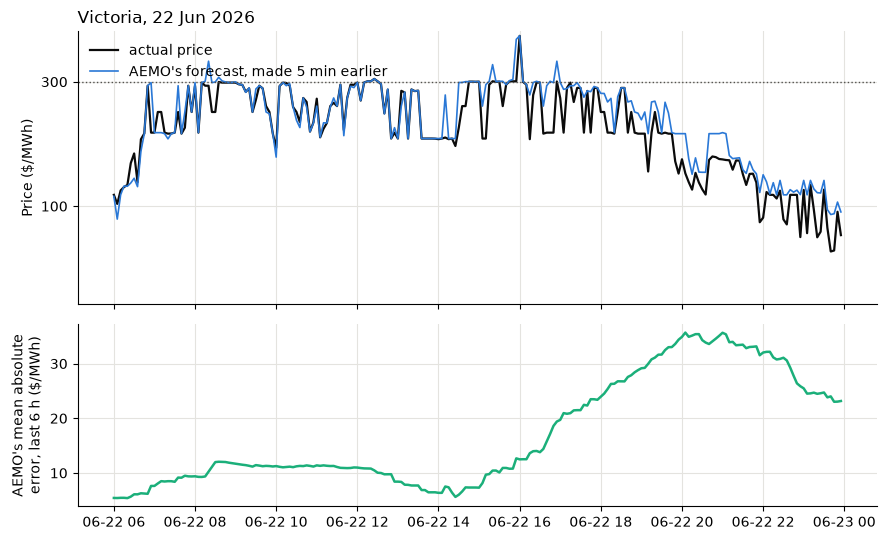

In [4]:
price = timeline.set_index("settlement_date")["rrp"]
test_start = experiment.test_df["settlement_date"].min()
starts = ((price >= 300) & (price.shift() < 300))[price.index >= test_start]
day = pd.Timestamp(starts.groupby(starts.index.date).sum().idxmax())
window = slice(day + pd.to_timedelta(6, unit="h"), day + pd.to_timedelta(23 * 60 + 55, unit="min"))
p5 = timeline.set_index("settlement_date")["p5_h05_rrp"]
aemo_5min_ago = pd.Series(p5.reindex(p5.index - pd.to_timedelta(5, unit="min")).to_numpy(), index=p5.index)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.plot(price.loc[window], color=INK, linewidth=1.6, label="actual price")
top.plot(aemo_5min_ago.loc[window], color=AEMO, linewidth=1.2, label="AEMO's forecast, made 5 min earlier")
top.axhline(300, color=MUTED, linewidth=1, linestyle=":")
top.set_yscale("symlog", linthresh=100)
shown = pd.concat([price.loc[window], aemo_5min_ago.loc[window]])
ticks = [t for t in (0, 100, 300, 1000, 3000, 10000) if shown.min() - 50 <= t <= shown.max() * 1.5]
top.set_yticks(ticks, [f"{t:,}" for t in ticks])
top.set_ylabel(r"Price (\$/MWh)")
top.legend(frameon=False, loc="upper left")
top.set_title(f"Victoria, {day:%d %b %Y}", loc="left")
bottom.plot(features["reliability_rrp_err05_abs_72"].loc[window], color=OURS, linewidth=1.8)
bottom.set_ylabel(r"AEMO's mean absolute" "\n" r"error, last 6 h (\$/MWh)")
for axis in (top, bottom):
    axis.grid(True, color="#e4e3df")
    axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

**Experiment**

The baseline MLP (class and settings from `main.py`) was trained with and without the 18 reliability
features; nothing else differs. The number of epochs is chosen on the validation period (Dec 2024 to Aug
2025), the model is refit on all pre-test data, and it is scored once on the test year (Sep 2025 to Jul
2026). Each configuration was trained with three seeds, since MLP error varies by a few percent between
seeds, giving 30 runs across the five states.

The runs were produced by `reliability_mlp.py`, which also writes the daily summary read below
(`reliability_results_5min.csv`). The summary is not stored in the repository, so the script must be run
before the cells below (about 10 minutes per run, six runs per state; omit `--regions` for all five states):

```bash
python model_research/connor/reliability_mlp.py --regions VIC1
```

In [5]:
results = pd.read_csv("reliability_results_5min.csv", parse_dates=["day"])
seeds = [42, 1, 2]
totals = results.groupby("region").sum(numeric_only=True)

rows = []
for region, row in totals.iterrows():
    for seed in seeds:
        rows.append({"state": region[:-1], "seed": seed,
                     "baseline": row[f"baseline_seed{seed}_abs"] / row["intervals"],
                     "+ reliability": row[f"reliability_seed{seed}_abs"] / row["intervals"]})
per_seed = pd.DataFrame(rows).set_index(["state", "seed"])
per_seed["change %"] = 100 * (per_seed["+ reliability"] / per_seed["baseline"] - 1)
print(f"The reliability features helped in {(per_seed['change %'] < 0).sum()} of {len(per_seed)} seed runs")
per_seed

The reliability features helped in 15 of 15 seed runs


baseline  + reliability  change %
state seed                                   
NSW   42       12.50          11.44     -8.44
      1        12.68          11.45     -9.67
      2        12.23          11.26     -7.96
QLD   42        5.94           5.19    -12.71
      1         6.15           5.23    -14.91
      2         6.46           5.48    -15.16
SA    42       16.66          14.84    -10.92
      1        16.44          15.12     -8.04
      2        16.79          15.01    -10.59
TAS   42        5.77           5.33     -7.57
      1         5.54           5.21     -5.95
      2         5.70           5.52     -3.00
VIC   42        5.88           5.22    -11.36
      1         5.85           5.72     -2.30
      2         5.86           5.15    -12.16

For each state, the three seeds' errors are averaged and the test year is resampled by whole days (1,000
draws) to give a 95% interval for the change. AEMO's 5-minute forecast and the error during $300+
intervals are shown for comparison.

In [6]:
rng = np.random.default_rng(0)
rows = []
for region, days in results.groupby("region"):
    base = days[[f"baseline_seed{s}_abs" for s in seeds]].mean(axis=1).to_numpy()
    rel = days[[f"reliability_seed{s}_abs" for s in seeds]].mean(axis=1).to_numpy()
    picks = rng.integers(0, len(days), size=(1000, len(days)))
    change = 100 * (rel[picks].sum(axis=1) / base[picks].sum(axis=1) - 1)
    n, spikes = days["intervals"].sum(), days["spike_intervals"].sum()
    spike_mae = lambda name: days[[f"{name}_seed{s}_spike_abs" for s in seeds]].mean(axis=1).sum() / spikes
    rows.append({"state": region[:-1], "baseline": base.sum() / n, "+ reliability": rel.sum() / n,
                 "change %": 100 * (rel.sum() / base.sum() - 1),
                 "95% interval": f"{np.quantile(change, 0.025):+.1f}% to {np.quantile(change, 0.975):+.1f}%",
                 "AEMO": days["aemo_abs"].sum() / n,
                 "spikes: baseline": spike_mae("baseline"), "spikes: + reliability": spike_mae("reliability"),
                 "spikes: AEMO": days["aemo_spike_abs"].sum() / spikes,
                 "low": np.quantile(change, 0.025), "high": np.quantile(change, 0.975)})
summary = pd.DataFrame(rows).set_index("state")
summary.drop(columns=["low", "high"])

,baseline,+ reliability,change %,95% interval,AEMO,spikes: baseline,spikes: + reliability,spikes: AEMO
state,,,,,,,,
NSW,12.47,11.39,-8.70,-10.9% to -6.5%,15.94,1197.99,1168.73,1186.36
QLD,6.18,5.30,-14.29,-15.3% to -13.2%,5.20,510.60,445.31,110.17
SA,16.63,14.99,-9.86,-11.9% to -8.1%,18.81,479.74,449.13,520.67
TAS,5.67,5.36,-5.51,-6.8% to -4.4%,3.08,1209.59,1178.21,192.64
VIC,5.87,5.36,-8.62,-9.9% to -7.2%,6.31,185.50,182.50,77.22


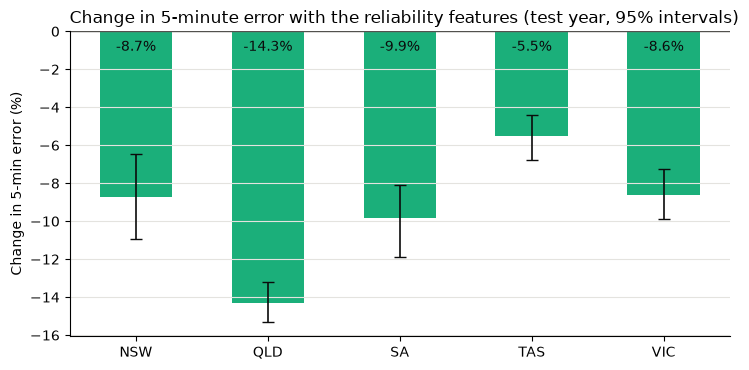

In [7]:
fig, axis = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(summary))
axis.bar(x, summary["change %"], color=OURS, width=0.55)
axis.errorbar(x, summary["change %"], yerr=[summary["change %"] - summary["low"], summary["high"] - summary["change %"]],
              fmt="none", ecolor=INK, capsize=4, linewidth=1.2)
for xi, value in zip(x, summary["change %"]):
    axis.annotate(f"{value:.1f}%", (xi, 0), xytext=(0, -14), textcoords="offset points", ha="center", color=INK)
axis.axhline(0, color=MUTED, linewidth=1)
axis.set_xticks(x, summary.index)
axis.set_ylabel("Change in 5-min error (%)")
axis.set_title("Change in 5-minute error with the reliability features (test year, 95% intervals)", loc="left")
axis.grid(True, axis="y", color="#e4e3df")
axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()